# **Importing Dataset and EDA**

In [1]:
import time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/domestic-flight-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv
/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv


In [3]:
train_raw  = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/train.csv')
test_raw   = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/test.csv')
sample_sub = pd.read_csv('/kaggle/input/competitions/domestic-flight-price-prediction-challenge/sample_submission.csv')
print("train:", train_raw.shape, "\ntest:", test_raw.shape, "\nsample submission:", sample_sub.shape)
train_raw.head()

train: (15589, 12) 
test: (3898, 11) 
sample submission: (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


In [4]:
METRIC          = "r2"     # <-- set to the competition metric
LOG_TARGET      = "auto"   # "auto", True or False
TARGET_COL, ID_COL = "price", "id"

In [5]:
info = pd.DataFrame({
    "dtype": train_raw.dtypes.astype(str),
    "n_unique": train_raw.nunique(),
    "missing_train_%": (100 * train_raw.isna().mean()).round(1),
    "missing_test_%": (100 * test_raw.reindex(columns=train_raw.columns).isna().mean()).round(1),
    "example": train_raw.iloc[0],
})
#print("Exact duplicate rows (ignoring id):", train_raw.drop(columns=ID_COL).duplicated().sum())
display(info)
for c in ["source_city", "departure_time", "stops", "arrival_time", "destination_city", "flight_class"]:
    print(f"{c}: {train_raw[c].value_counts().to_dict()}\n")



,dtype,n_unique,missing_train_%,missing_test_%,example
id,int64,15589,0.0,0.0,1
airline,object,18,19.8,20.5,Wayfarer Aviation
flight,object,1070,0.0,0.0,IX 1070
source_city,object,6,0.0,0.0,Metropolis
departure_time,object,6,0.0,0.0,Evening
stops,object,3,0.0,0.0,zero
arrival_time,object,6,0.0,0.0,Night
destination_city,object,6,0.0,0.0,Springfield
flight_class,object,2,0.0,0.0,Economy
duration,float64,243,19.9,19.9,NaN


source_city: {'Metropolis': 6198, 'Night City': 2651, 'Springfield': 2051, 'Hill Valley': 1600, 'Gotham': 1586, 'Los Santos': 1503}

departure_time: {'Evening': 3304, 'Morning': 3296, 'Night': 2832, 'Early_Morning': 2680, 'Afternoon': 2462, 'Late_Night': 1015}

stops: {'zero': 10965, 'one': 4558, 'two_or_more': 66}

arrival_time: {'Night': 3845, 'Morning': 3116, 'Evening': 2968, 'Afternoon': 2860, 'Late_Night': 1826, 'Early_Morning': 974}

destination_city: {'Night City': 4663, 'Springfield': 2870, 'Metropolis': 2759, 'Hill Valley': 2126, 'Los Santos': 1609, 'Gotham': 1562}

flight_class: {'Economy': 9209, 'Business': 6380}



count     15589.0
mean      29817.0
std       39128.0
min        3801.0
25%        7210.0
50%       10183.0
75%       35968.0
max      323177.0
Name: price, dtype: float64

Skewness: raw price = 2.70 
log(1 + price) = 0.71


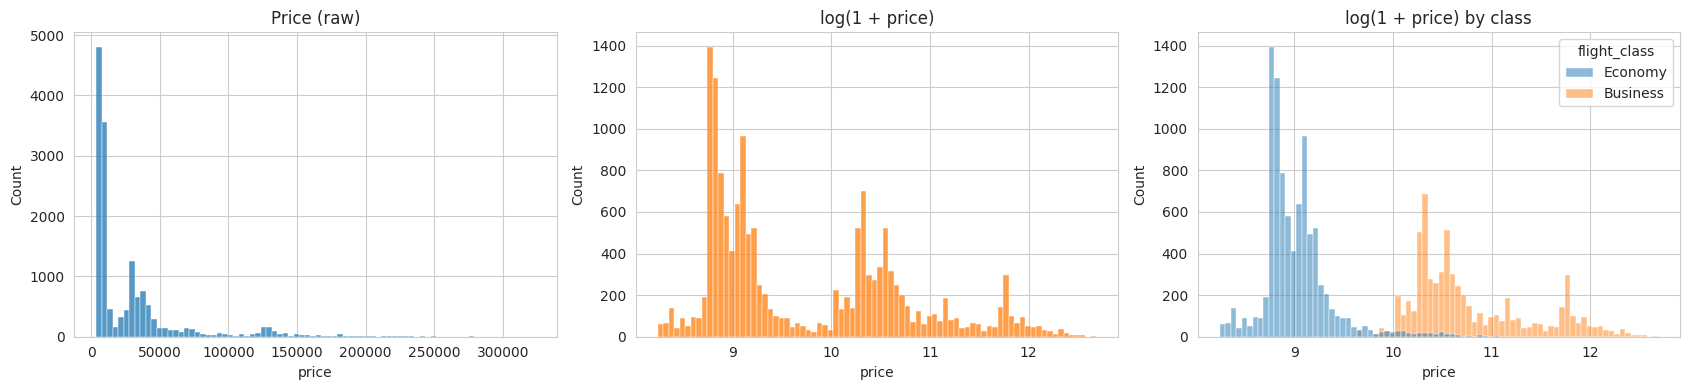

,count,mean,std,min,25%,50%,75%,max
flight_class,,,,,,,,
Business,6380.0,60127.0,46415.0,15544.0,30767.0,38546.0,70441.0,323177.0
Economy,9209.0,8818.0,4670.0,3801.0,6740.0,7587.0,9340.0,74691.0


In [6]:
y_all = train_raw[TARGET_COL]
print(y_all.describe().round(0))

print(f"\nSkewness: raw price = {y_all.skew():.2f} \nlog(1 + price) = {np.log1p(y_all).skew():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(y_all, bins=80, ax=ax[0]); ax[0].set_title("Price (raw)")
sns.histplot(np.log1p(y_all), bins=80, ax=ax[1], color="tab:orange"); ax[1].set_title("log(1 + price)")
sns.histplot(data=train_raw, x=np.log1p(y_all), hue="flight_class", bins=80, ax=ax[2]); ax[2].set_title("log(1 + price) by class")
plt.tight_layout(); plt.show()
display(train_raw.groupby("flight_class")[TARGET_COL].describe().round(0))

In [7]:
all_feat = train_raw.drop(columns=TARGET_COL).copy()
all_feat["carrier"] = all_feat["flight"].str.split().str[0]

carrier_map = all_feat.dropna(subset=["airline"]).groupby("carrier")["airline"].agg(["nunique", lambda s: s.mode()[0], "size"])
carrier_map.columns = ["airlines_per_carrier_code", "airline", "rows"]
display(carrier_map.sort_values("rows", ascending=False))
miss = all_feat["airline"].isna()
print(f"Rows with missing airline whose carrier code identifies a unique airline: "
      f"{all_feat.loc[miss, 'carrier'].isin(carrier_map.index[carrier_map.airlines_per_carrier_code == 1]).mean():.1%}")

keys = ["flight", "source_city", "destination_city", "stops"]
grp = all_feat.dropna(subset=["duration"]).groupby(keys)["duration"]
print(f"\nSame flight + route + stops: median std of duration = {grp.std().median():.2f} h "
      f"({(grp.nunique() == 1).mean():.0%} of groups have exactly one duration)")
dmiss = all_feat[all_feat["duration"].isna()].set_index(keys).index
print(f"Rows with missing duration that have a matching group: {dmiss.isin(grp.size().index).mean():.1%}")

,airlines_per_carrier_code,airline,rows
carrier,,,
6E,1,Oceanic Airlines,5112
AI,1,Wayfarer Aviation,4783
QP,1,Sandpiper Air,697
IX,1,Wayfarer Aviation,417
EK,1,Stark Aviation,336
UL,1,Ajira Airways,330
EY,1,Nakatomi Airlines,319
TG,1,Wayne Enterprises Air,180
SG,1,Vandelay Aviation,115


Rows with missing airline whose carrier code identifies a unique airline: 100.0%

Same flight + route + stops: median std of duration = 0.00 h (82% of groups have exactly one duration)
Rows with missing duration that have a matching group: 96.6%


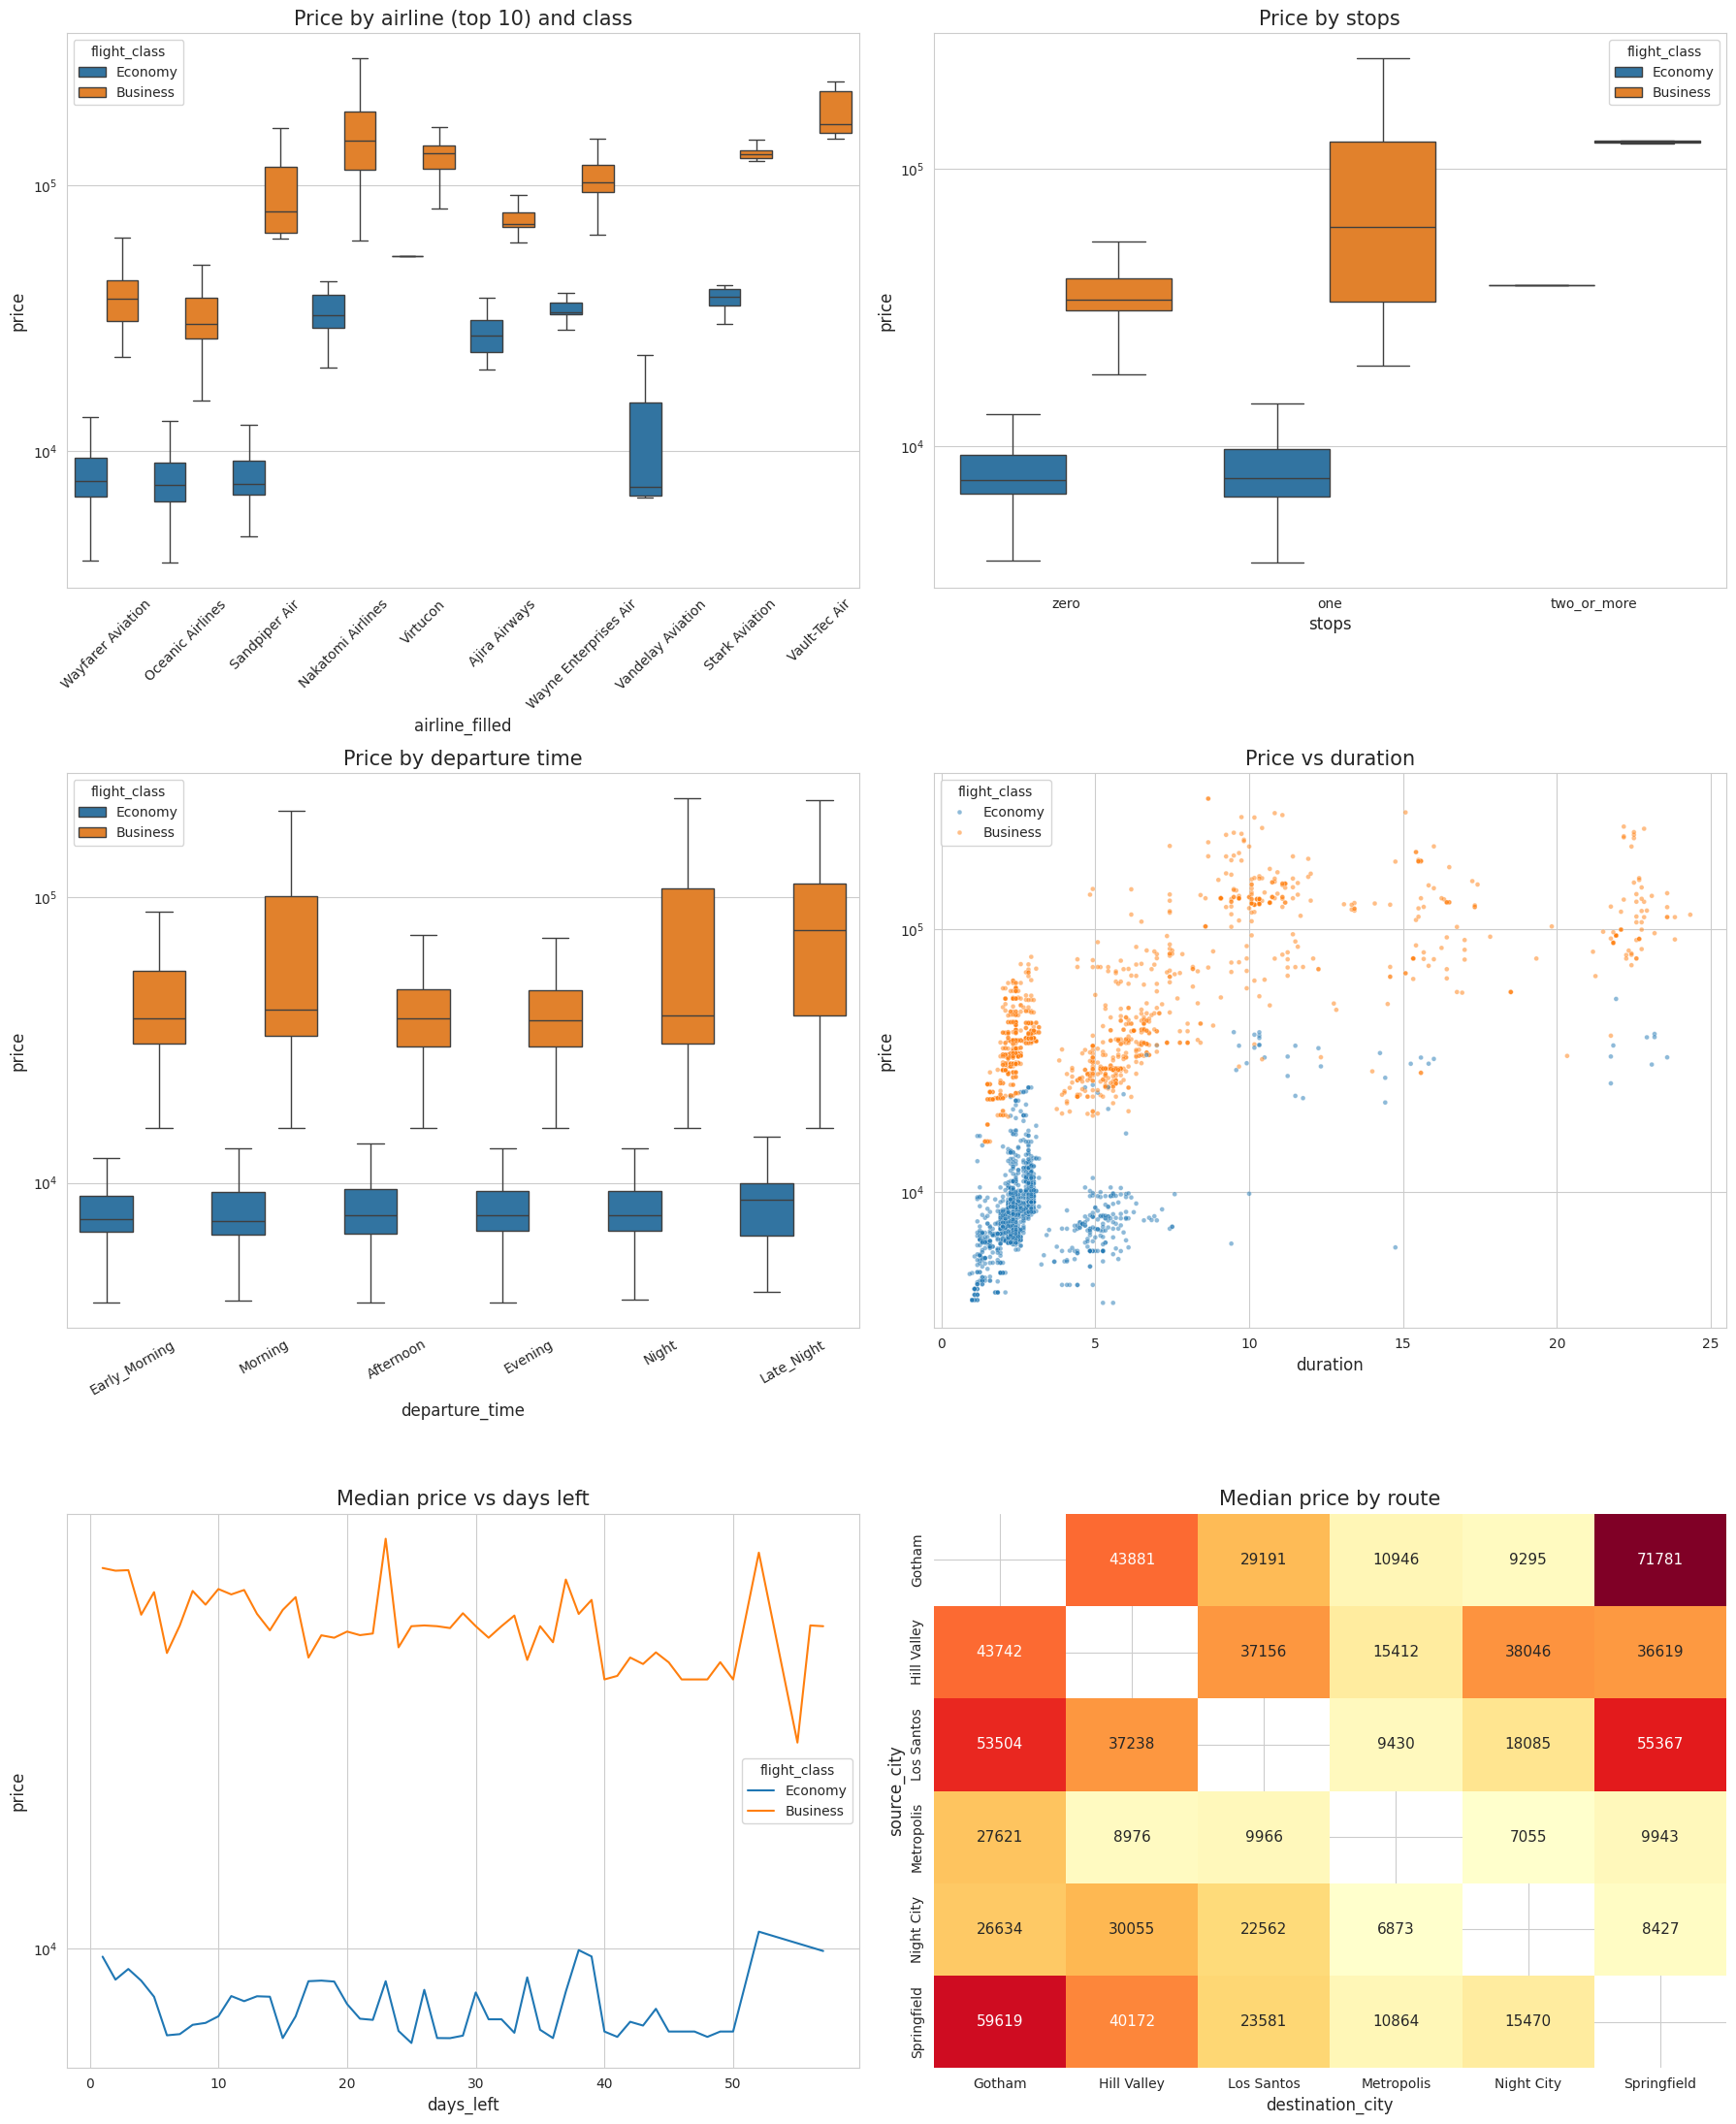

           duration  days_left  price
duration      1.000     -0.023  0.699
days_left    -0.023      1.000 -0.023
price         0.699     -0.023  1.000


In [8]:
df = train_raw.copy()
df["carrier"] = df["flight"].str.split().str[0]
df["airline_filled"] = df["airline"].fillna(df["carrier"].map(carrier_map["airline"]))
ORDER_TIME = ["Early_Morning", "Morning", "Afternoon", "Evening", "Night", "Late_Night"]

fig, ax = plt.subplots(3, 2, figsize=(18, 22))

top_air = df["airline_filled"].value_counts().index[:10]
sns.boxplot(data=df[df.airline_filled.isin(top_air)], x="airline_filled", y=TARGET_COL, hue="flight_class", ax=ax[0, 0], showfliers=False)
ax[0, 0].set_yscale("log"); ax[0, 0].tick_params(axis="x", rotation=45); ax[0, 0].set_title("Price by airline (top 10) and class")

sns.boxplot(data=df, x="stops", y=TARGET_COL, hue="flight_class", order=["zero", "one", "two_or_more"], ax=ax[0, 1], showfliers=False)
ax[0, 1].set_yscale("log"); ax[0, 1].set_title("Price by stops")

sns.boxplot(data=df, x="departure_time", y=TARGET_COL, hue="flight_class", order=ORDER_TIME, ax=ax[1, 0], showfliers=False)
ax[1, 0].set_yscale("log"); ax[1, 0].tick_params(axis="x", rotation=30); ax[1, 0].set_title("Price by departure time")

sns.scatterplot(data=df.sample(4000, random_state=0), x="duration", y=TARGET_COL, hue="flight_class", s=12, alpha=0.5, ax=ax[1, 1])
ax[1, 1].set_yscale("log"); ax[1, 1].set_title("Price vs duration")

sns.lineplot(data=df, x="days_left", y=TARGET_COL, hue="flight_class", estimator="median", errorbar=None, ax=ax[2, 0])
ax[2, 0].set_yscale("log"); ax[2, 0].set_title("Median price vs days left")

route = df.groupby(["source_city", "destination_city"])[TARGET_COL].median().unstack()
sns.heatmap(route, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax[2, 1], cbar=False, annot_kws={"size": 11})
ax[2, 1].set_title("Median price by route")

for a in ax.flat:
    a.title.set_fontsize(15)
    a.xaxis.label.set_fontsize(12); a.yaxis.label.set_fontsize(12)
plt.tight_layout(); plt.show()

print(df[["duration", "days_left", TARGET_COL]].corr().round(3))

In [9]:
for cls, g in train_raw.groupby("flight_class"):
    q1, q3 = g[TARGET_COL].quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
    print(f"{cls:9s}: IQR upper fence = {upper:>9,.0f} | rows above = {(g[TARGET_COL] > upper).sum()} ({(g[TARGET_COL] > upper).mean():.1%})")

Business : IQR upper fence =   129,952 | rows above = 771 (12.1%)
Economy  : IQR upper fence =    13,240 | rows above = 611 (6.6%)


In [10]:
REMOVE_OUTLIERS = False

# **Preprocessing Pipeline**

In [11]:
STOPS = {"zero": 0, "one": 1, "two_or_more": 2}

class FlightFeatures(BaseEstimator, TransformerMixin):
    # smart=True: recover airline / duration from the flight code (lookups learned in fit).
    # smart=False: leave them missing for the simple median / 'Unknown' imputers later in the pipeline.
    def __init__(self, smart=True, interactions=False):
        self.smart, self.interactions = smart, interactions

    def fit(self, X, y=None):
        X = self._base(X)
        known = X.dropna(subset=["airline"])
        self.carrier_airline_ = known.groupby("carrier")["airline"].agg(lambda s: s.mode()[0])
        d = X.dropna(subset=["duration"])
        self.dur_flight_ = d.groupby(["flight", "source_city", "destination_city", "stops_num"])["duration"].median()
        self.dur_route_ = d.groupby(["source_city", "destination_city", "stops_num"])["duration"].median()
        self.dur_all_ = d["duration"].median()
        return self

    def _base(self, X):
        X = X.copy()
        X["carrier"] = X["flight"].astype(str).str.split().str[0]
        X["stops_num"] = X["stops"].map(STOPS)
        return X

    def transform(self, X):
        X = self._base(X)
        if self.smart:
            X["airline"] = X["airline"].fillna(X["carrier"].map(self.carrier_airline_))
            for table, keys in [(self.dur_flight_, ["flight", "source_city", "destination_city", "stops_num"]),
                                (self.dur_route_, ["source_city", "destination_city", "stops_num"])]:
                lookup = pd.Series(table.reindex(pd.MultiIndex.from_frame(X[keys])).values, index=X.index)
                X["duration"] = X["duration"].fillna(lookup)
            X["duration"] = X["duration"].fillna(self.dur_all_)
        X["is_business"] = (X["flight_class"] == "Business").astype(int)
        X["route"] = X["source_city"] + " -> " + X["destination_city"]
        cats = CAT_COLS + (INTER_COLS if self.interactions else [])
        if self.interactions:
            for base in ["airline", "route", "departure_time", "arrival_time"]:
                X[base + "_x_class"] = X[base].astype(str) + " | " + X["flight_class"].astype(str)
        out = X[NUM_COLS + cats].copy()
        out[cats] = out[cats].astype(object)
        return out

NUM_COLS = ["duration", "days_left", "stops_num", "is_business"]
CAT_COLS = ["airline", "carrier", "source_city", "destination_city", "route", "departure_time", "arrival_time"]
INTER_COLS = ["airline_x_class", "route_x_class", "departure_time_x_class", "arrival_time_x_class"]

LOG = {"linear": True, "tree": True} if LOG_TARGET == "auto" else {"linear": LOG_TARGET, "tree": LOG_TARGET}

def wrap(pipe, family, use_log):
    # Optionally train on log(1 + price); predictions are converted back to rupees automatically.
    use_log = LOG[family] if use_log is None else use_log
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1, check_inverse=False) if use_log else pipe

def unwrap(p):
    return p.regressor_ if hasattr(p, "regressor_") else p

def linear_pipe(model, poly_degree=None, smart=True, interactions=True, use_log=None):
    num = [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    if poly_degree:
        num += [("poly", PolynomialFeatures(degree=poly_degree, include_bias=False)), ("scale2", StandardScaler())]
    prep = ColumnTransformer([
        ("num", Pipeline(num), NUM_COLS),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         CAT_COLS + (INTER_COLS if interactions else []))])
    return wrap(Pipeline([("fe", FlightFeatures(smart=smart, interactions=interactions)), ("prep", prep), ("model", model)]), "linear", use_log)

def tree_pipe(model, smart=True, use_log=None):
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), CAT_COLS)])
    return wrap(Pipeline([("fe", FlightFeatures(smart=smart)), ("prep", prep), ("model", model)]), "tree", use_log)

check = FlightFeatures().fit(train_raw)
print("Missing values after FlightFeatures on test:\n", check.transform(test_raw).isna().sum().to_dict())
check.transform(train_raw).head()

Missing values after FlightFeatures on test:
 {'duration': 0, 'days_left': 0, 'stops_num': 0, 'is_business': 0, 'airline': 0, 'carrier': 0, 'source_city': 0, 'destination_city': 0, 'route': 0, 'departure_time': 0, 'arrival_time': 0}


,duration,days_left,stops_num,is_business,airline,carrier,source_city,destination_city,route,departure_time,arrival_time
0,2.92,18,0,0,Wayfarer Aviation,IX,Metropolis,Springfield,Metropolis -> Springfield,Evening,Night
1,1.33,38,0,0,Oceanic Airlines,6E,Los Santos,Springfield,Los Santos -> Springfield,Night,Night
2,2.08,13,0,1,Wayfarer Aviation,AI,Night City,Springfield,Night City -> Springfield,Evening,Night
3,2.25,5,0,0,Oceanic Airlines,6E,Night City,Metropolis,Night City -> Metropolis,Afternoon,Evening
4,4.83,21,1,0,Oceanic Airlines,6E,Hill Valley,Springfield,Hill Valley -> Springfield,Evening,Night


In [12]:
data = train_raw.copy()
if REMOVE_OUTLIERS:
    keep = pd.Series(True, index=data.index)
    for cls, g in data.groupby("flight_class"):
        q1, q3 = g[TARGET_COL].quantile([0.25, 0.75])
        keep[g.index] = g[TARGET_COL] <= q3 + 1.5 * (q3 - q1)
    print(f"Removing {(~keep).sum()} outlier rows"); data = data[keep]

X = data.drop(columns=[TARGET_COL, ID_COL]); y = data[TARGET_COL].values
X_test = test_raw.drop(columns=[ID_COL])
VALID_SIZE = 0.2
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=VALID_SIZE, random_state=RANDOM_STATE,
                                            stratify=X["flight_class"])
print("train:", X_tr.shape, "| valid:", X_val.shape)


def score(y_true, y_pred, metric=METRIC):
    y_pred = np.maximum(y_pred, 0)
    if metric == "rmse":  return np.sqrt(mean_squared_error(y_true, y_pred))
    if metric == "mae":   return mean_absolute_error(y_true, y_pred)
    if metric == "r2":    return r2_score(y_true, y_pred)
    if metric == "rmsle": return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))
    if metric == "mape":  return np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    raise ValueError(metric)
HIGHER_IS_BETTER = METRIC == "r2"
pick = (lambda s: s.idxmax()) if HIGHER_IS_BETTER else (lambda s: s.idxmin())

RESULTS = {}
def evaluate(name, pipe, note="", record=True):
    t0 = time.time()
    pipe.fit(X_tr, y_tr)
    p_tr, p_val = (pipe.predict(X_tr)), (pipe.predict(X_val))
    r = {"pipe": pipe, "train": score(y_tr, p_tr), "valid": score(y_val, p_val),
         "valid_R2": r2_score(y_val, np.maximum(p_val, 0)), "note": note, "secs": time.time() - t0}
    if record: RESULTS[name] = r
    print(f"{name:34s} train {METRIC.upper()} = {r['train']:>10.4f} | valid {METRIC.upper()} = {r['valid']:>10.4f} | valid R² = {r['valid_R2']:.4f}")
    return r

def tune(name, make_pipe, param, grid, note="", logx=None):
    rows = []
    for v in grid:
        p = make_pipe(v); p.fit(X_tr, y_tr)
        rows.append((v, score(y_tr, (p.predict(X_tr))), score(y_val, (p.predict(X_val)))))
    df = pd.DataFrame(rows, columns=[param, "train", "valid"])
    best = df.loc[pick(df["valid"]), param]
    plt.figure(figsize=(7, 3.5))
    plt.plot(df[param], df["train"], "o-", label="train"); plt.plot(df[param], df["valid"], "o-", label="validation")
    plt.axvline(best, ls="--", c="grey")
    if logx or (logx is None and min(grid) > 0 and max(grid) / min(grid) > 50): plt.xscale("log")
    plt.xlabel(param); plt.ylabel(METRIC.upper()); plt.title(f"{name}: tuning {param} (best = {best:g})")
    plt.legend(); plt.tight_layout(); plt.show()
    evaluate(name, make_pipe(best), note=f"{param}={best:g}. {note}".strip())
    return best

train: (12471, 10) | valid: (3118, 10)


# **Models**

In [13]:
quick_tree = lambda: DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE)

print("1) Imputation")
for smart in [False, True]:
    tag = "flight-code lookup" if smart else "simple median/Unknown"
    evaluate(f"   Linear Reg  [{tag}]", linear_pipe(LinearRegression(), smart=smart, interactions=False), record=False)
    evaluate(f"   Tree d=12   [{tag}]", tree_pipe(quick_tree(), smart=smart), record=False)

print("\n2) Class-interaction features (linear model)")
for inter in [False, True]:
    evaluate(f"   Linear Reg  [interactions={inter}]", linear_pipe(LinearRegression(), interactions=inter), record=False)

print("\n3) Target transform (chosen separately for linear and tree models)")
tt = {"linear": {}, "tree": {}}
for use_log in [False, True]:
    tag = "log" if use_log else "raw"
    tt["linear"][use_log] = evaluate(f"   Linear Reg  [{tag} target]", linear_pipe(LinearRegression(), use_log=use_log), record=False)["valid"]
    tt["tree"][use_log]   = evaluate(f"   Tree d=12   [{tag} target]", tree_pipe(quick_tree(), use_log=use_log), record=False)["valid"]
if LOG_TARGET == "auto":
    for fam in LOG:
        LOG[fam] = (tt[fam][True] > tt[fam][False]) if HIGHER_IS_BETTER else (tt[fam][True] < tt[fam][False])
for fam in LOG:
    print(f"==> {fam} models will be trained on {'log(1 + price)' if LOG[fam] else 'raw price'}")

1) Imputation
   Linear Reg  [simple median/Unknown] train R2 =     0.8456 | valid R2 =     0.8346 | valid R² = 0.8346
   Tree d=12   [simple median/Unknown] train R2 =     0.9405 | valid R2 =     0.8947 | valid R² = 0.8947
   Linear Reg  [flight-code lookup] train R2 =     0.8403 | valid R2 =     0.8325 | valid R² = 0.8325
   Tree d=12   [flight-code lookup] train R2 =     0.9522 | valid R2 =     0.9065 | valid R² = 0.9065

2) Class-interaction features (linear model)
   Linear Reg  [interactions=False] train R2 =     0.8403 | valid R2 =     0.8325 | valid R² = 0.8325
   Linear Reg  [interactions=True] train R2 =     0.8665 | valid R2 =     0.8637 | valid R² = 0.8637

3) Target transform (chosen separately for linear and tree models)
   Linear Reg  [raw target]        train R2 =     0.8903 | valid R2 =     0.8784 | valid R² = 0.8784
   Tree d=12   [raw target]        train R2 =     0.9486 | valid R2 =     0.8898 | valid R² = 0.8898
   Linear Reg  [log target]        train R2 =     0.8

## **Linear Regression (base)**

In [14]:
evaluate("Linear Regression", linear_pipe(LinearRegression()), "Baseline OLS")

Linear Regression                  train R2 =     0.8903 | valid R2 =     0.8784 | valid R² = 0.8784


{'pipe': Pipeline(steps=[('fe', FlightFeatures(interactions=True)),
                 ('prep',
                  ColumnTransformer(transformers=[('num',
                                                   Pipeline(steps=[('impute',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['duration', 'days_left',
                                                    'stops_num',
                                                    'is_business']),
                                                  ('cat',
                                                   Pipeline(steps=[('impute',
                                                                    SimpleImputer(fill_value='Unknown',
                                                  

### Ridge regression (L2), tuning α

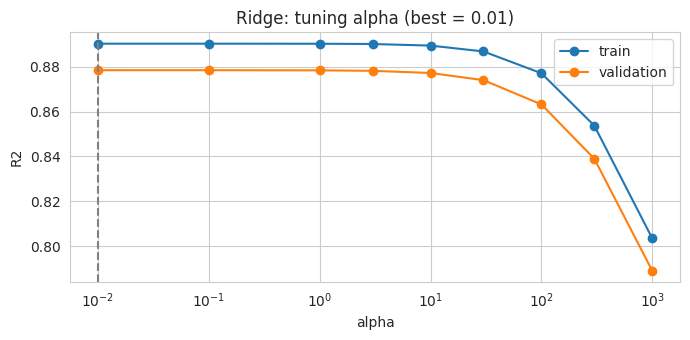

Ridge                              train R2 =     0.8903 | valid R2 =     0.8784 | valid R² = 0.8784


np.float64(0.01)

In [15]:
tune("Ridge", lambda a: linear_pipe(Ridge(alpha=a)), "alpha", [0.01, 0.1, 1, 3, 10, 30, 100, 300, 1000])

### Lasso regression (L1), tuning α

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.550e+11, tolerance: 1.891e+09
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.571e+11, tolerance: 1.891e+09
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.644e+11, tolerance: 1.891e

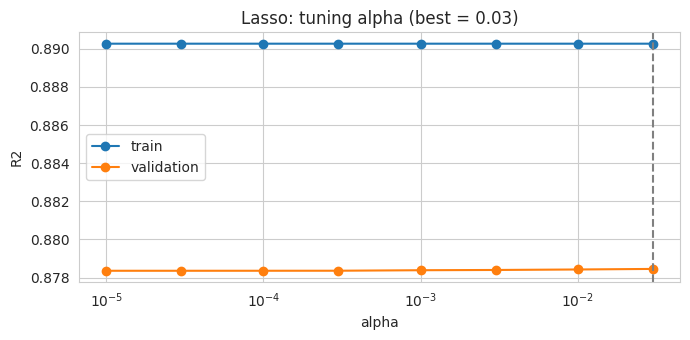

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.507e+11, tolerance: 1.891e+09
  model = cd_fast.enet_coordinate_descent(


Lasso                              train R2 =     0.8903 | valid R2 =     0.8785 | valid R² = 0.8785


np.float64(0.03)

In [16]:
tune("Lasso", lambda a: linear_pipe(Lasso(alpha=a, max_iter=20000)), "alpha", [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2])

Lasso kept 132 of 206 features and zeroed 74:
['cat__airline_Ajira Airways', 'cat__airline_Hooli Airways', 'cat__airline_Vandelay Aviation', 'cat__carrier_EK', 'cat__carrier_EY', 'cat__carrier_FZ', 'cat__carrier_GF', 'cat__carrier_KU', 'cat__carrier_MH', 'cat__carrier_QR', 'cat__carrier_SQ', 'cat__carrier_TG', 'cat__carrier_UL', 'cat__source_city_Gotham', 'cat__source_city_Los Santos', 'cat__source_city_Metropolis', 'cat__source_city_Springfield', 'cat__destination_city_Hill Valley', 'cat__destination_city_Los Santos', 'cat__destination_city_Metropolis', 'cat__destination_city_Springfield', 'cat__route_Gotham -> Hill Valley', 'cat__route_Gotham -> Los Santos', 'cat__route_Gotham -> Metropolis', 'cat__route_Gotham -> Night City', 'cat__route_Gotham -> Springfield', 'cat__route_Hill Valley -> Gotham', 'cat__route_Hill Valley -> Los Santos', 'cat__route_Hill Valley -> Metropolis', 'cat__route_Hill Valley -> Springfield', 'cat__route_Los Santos -> Gotham', 'cat__route_Los Santos -> Hill Va

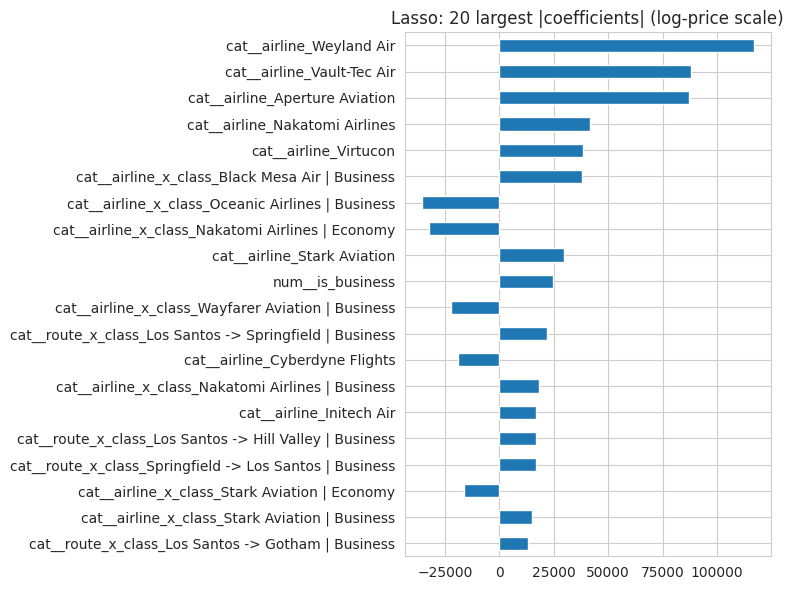

In [17]:
lp = unwrap(RESULTS["Lasso"]["pipe"])
coefs = pd.Series(lp.named_steps["model"].coef_, index=lp.named_steps["prep"].get_feature_names_out())
print(f"Lasso kept {(coefs != 0).sum()} of {len(coefs)} features and zeroed {(coefs == 0).sum()}:")
print(list(coefs[coefs == 0].index))
coefs[coefs != 0].sort_values(key=abs).tail(20).plot.barh(figsize=(8, 6), title="Lasso: 20 largest |coefficients| (log-price scale)")
plt.tight_layout(); plt.show()

## **Polynomial Regression**

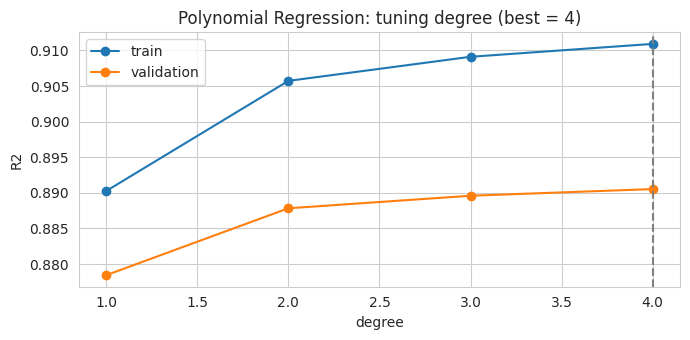

Polynomial Regression              train R2 =     0.9109 | valid R2 =     0.8905 | valid R² = 0.8905


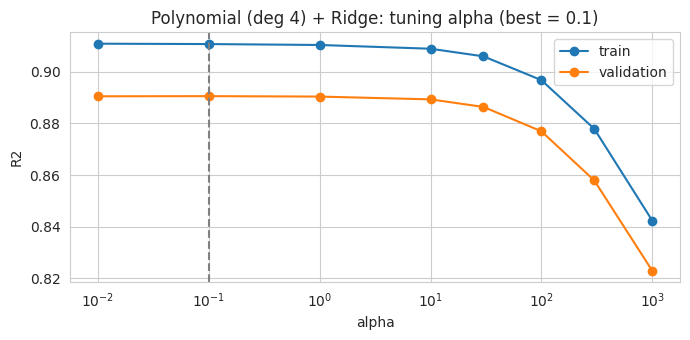

Polynomial (deg 4) + Ridge         train R2 =     0.9107 | valid R2 =     0.8906 | valid R² = 0.8906


np.float64(0.1)

In [18]:
best_deg = tune("Polynomial Regression", lambda d: linear_pipe(LinearRegression(), poly_degree=int(d)), "degree", [1, 2, 3, 4], logx=False)
tune(f"Polynomial (deg {int(best_deg)}) + Ridge", lambda a: linear_pipe(Ridge(alpha=a), poly_degree=int(best_deg)),
     "alpha", [0.01, 0.1, 1, 10, 30, 100, 300, 1000])

## **Regression Tree (unpruned)**

In [19]:
r = evaluate("Regression Tree (unpruned)", tree_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)))
t = unwrap(r["pipe"]).named_steps["model"]; print(f"depth = {t.get_depth()}, leaves = {t.get_n_leaves()}")

Regression Tree (unpruned)         train R2 =     0.9993 | valid R2 =     0.8665 | valid R² = 0.8665
depth = 32, leaves = 7867


### Pre-pruning

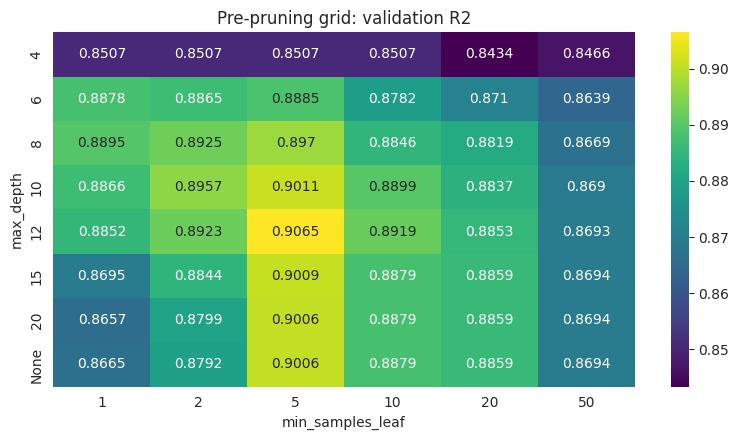

Regression Tree (pre-pruned)       train R2 =     0.9522 | valid R2 =     0.9065 | valid R² = 0.9065
depth = 12, leaves = 658


In [20]:
depths, leaves = [4, 6, 8, 10, 12, 15, 20, None], [1, 2, 5, 10, 20, 50]
rows = []
for d in depths:
    for l in leaves:
        p = tree_pipe(DecisionTreeRegressor(max_depth=d, min_samples_leaf=l, random_state=RANDOM_STATE)).fit(X_tr, y_tr)
        rows.append({"max_depth": str(d), "min_samples_leaf": l, "valid": score(y_val, (p.predict(X_val)))})
g = pd.DataFrame(rows)
plt.figure(figsize=(8, 4.5))
sns.heatmap(g.pivot(index="max_depth", columns="min_samples_leaf", values="valid").loc[[str(d) for d in depths]],
            annot=True, fmt=".4g", cmap="viridis" if HIGHER_IS_BETTER else "viridis_r")
plt.title(f"Pre-pruning grid: validation {METRIC.upper()}"); plt.tight_layout(); plt.show()

b = g.loc[pick(g["valid"])]; bd = None if b["max_depth"] == "None" else int(b["max_depth"]); bl = int(b["min_samples_leaf"])
r = evaluate("Regression Tree (pre-pruned)", tree_pipe(DecisionTreeRegressor(max_depth=bd, min_samples_leaf=bl, random_state=RANDOM_STATE)),
             f"max_depth={bd}, min_samples_leaf={bl}")
t = unwrap(r["pipe"]).named_steps["model"]; print(f"depth = {t.get_depth()}, leaves = {t.get_n_leaves()}")

## Post-pruning

5648 alphas on the pruning path; trying 40


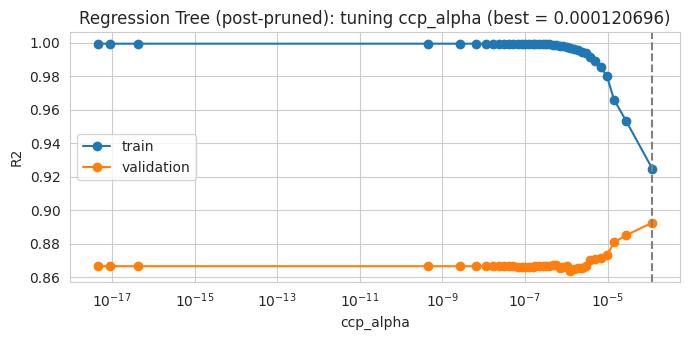

Regression Tree (post-pruned)      train R2 =     0.9247 | valid R2 =     0.8925 | valid R² = 0.8925
depth = 10, leaves = 80


In [21]:
pp = tree_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE), use_log=False)   # unwrapped, to reach the preprocessing steps
Xtr_t = Pipeline(pp.steps[:-1]).fit(X_tr).transform(X_tr)
y_path = np.log1p(y_tr) if LOG["tree"] else y_tr
path = DecisionTreeRegressor(random_state=RANDOM_STATE).cost_complexity_pruning_path(Xtr_t, y_path)
alphas = np.unique(np.quantile(path.ccp_alphas[:-1], np.linspace(0, 0.99, 40)))
print(f"{len(path.ccp_alphas)} alphas on the pruning path; trying {len(alphas)}")
alphas = alphas[alphas > 0] if (alphas > 0).sum() > 5 else alphas
tune("Regression Tree (post-pruned)", lambda a: tree_pipe(DecisionTreeRegressor(ccp_alpha=a, random_state=RANDOM_STATE)), "ccp_alpha", list(alphas), logx=True)
t = unwrap(RESULTS["Regression Tree (post-pruned)"]["pipe"]).named_steps["model"]; print(f"depth = {t.get_depth()}, leaves = {t.get_n_leaves()}")

## **Random Forest**

In [22]:
rows = []
for mf in [0.3, 0.5, 0.7, 1.0]:
    for msl in [1, 2, 5]:
        p = tree_pipe(RandomForestRegressor(n_estimators=150, max_features=mf, min_samples_leaf=msl, n_jobs=-1, random_state=RANDOM_STATE)).fit(X_tr, y_tr)
        rows.append({"max_features": mf, "min_samples_leaf": msl, "valid": score(y_val, (p.predict(X_val)))})
rf = pd.DataFrame(rows)
display(rf.pivot(index="max_features", columns="min_samples_leaf", values="valid").round(4))
b = rf.loc[pick(rf["valid"])]
evaluate("Random Forest", tree_pipe(RandomForestRegressor(n_estimators=300, max_features=b["max_features"], min_samples_leaf=int(b["min_samples_leaf"]),
                                                         n_jobs=-1, random_state=RANDOM_STATE)),
         f"max_features={b['max_features']}, min_samples_leaf={int(b['min_samples_leaf'])}, 300 trees")

min_samples_leaf,1,2,5
max_features,,,
0.3,0.9151,0.9144,0.9034
0.5,0.9166,0.9163,0.9106
0.7,0.9177,0.9170,0.9126
1.0,0.9152,0.9152,0.9099


Random Forest                      train R2 =     0.9890 | valid R2 =     0.9170 | valid R² = 0.9170


{'pipe': TransformedTargetRegressor(check_inverse=False, func=<ufunc 'log1p'>,
                            inverse_func=<ufunc 'expm1'>,
                            regressor=Pipeline(steps=[('fe', FlightFeatures()),
                                                      ('prep',
                                                       ColumnTransformer(transformers=[('num',
                                                                                        SimpleImputer(strategy='median'),
                                                                                        ['duration',
                                                                                         'days_left',
                                                                                         'stops_num',
                                                                                         'is_business']),
                                                                                       ('cat

# **Results and Comparison**

,train_r2,valid_r2,valid_R2,fit_secs,best params / note,public_LB
Random Forest,0.989035,0.917011,0.917011,4.512316,"max_features=0.7, min_samples_leaf=1, 300 trees",
Regression Tree (pre-pruned),0.952157,0.906456,0.906456,0.280246,"max_depth=12, min_samples_leaf=5",
Regression Tree (post-pruned),0.924665,0.892462,0.892462,0.826856,ccp_alpha=0.000120696.,
Polynomial (deg 4) + Ridge,0.910718,0.890557,0.890557,0.690408,alpha=0.1.,
Polynomial Regression,0.910927,0.890534,0.890534,0.793859,degree=4.,
Lasso,0.890263,0.878454,0.878454,43.098637,alpha=0.03.,
Linear Regression,0.890263,0.87844,0.87844,0.684752,Baseline OLS,
Ridge,0.890263,0.878439,0.878439,0.54998,alpha=0.01.,
Regression Tree (unpruned),0.99933,0.866492,0.866492,0.309716,,


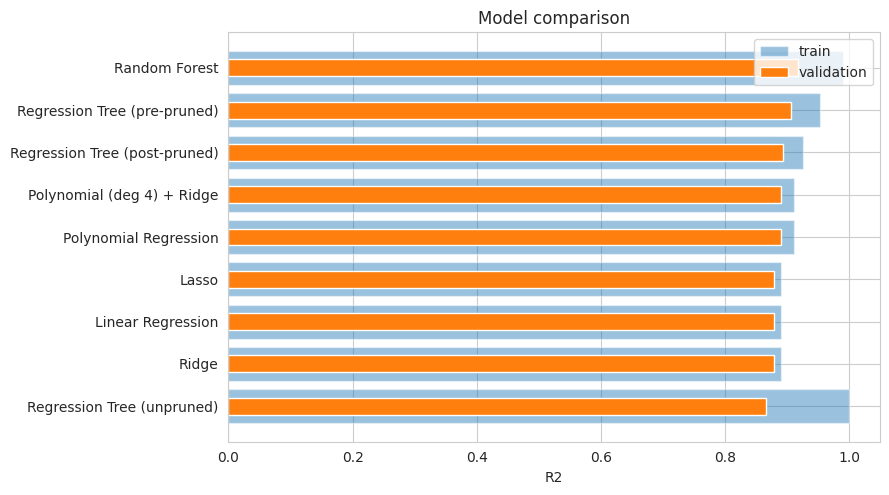

In [23]:
res = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "pipe"} for k, v in RESULTS.items()}).T
res = res[["train", "valid", "valid_R2", "secs", "note"]]
res.columns = [f"train_{METRIC}", f"valid_{METRIC}", "valid_R2", "fit_secs", "best params / note"]
res = res.sort_values(f"valid_{METRIC}", ascending=not HIGHER_IS_BETTER)
res["public_LB"] = ""
display(res)

order = res.index[::-1]
plt.figure(figsize=(9, 0.45 * len(res) + 1))
plt.barh(order, res.loc[order, f"train_{METRIC}"].astype(float), alpha=0.45, label="train")
plt.barh(order, res.loc[order, f"valid_{METRIC}"].astype(float), height=0.4, label="validation")
plt.xlabel(METRIC.upper()); plt.title("Model comparison"); plt.legend(); plt.tight_layout(); plt.show()

Mean absolute error by class:
 class
Business    7421.0
Economy      651.0
Name: abs_err, dtype: float64
(If the metric is RMSE/MAE, the Business-class errors dominate the score.)


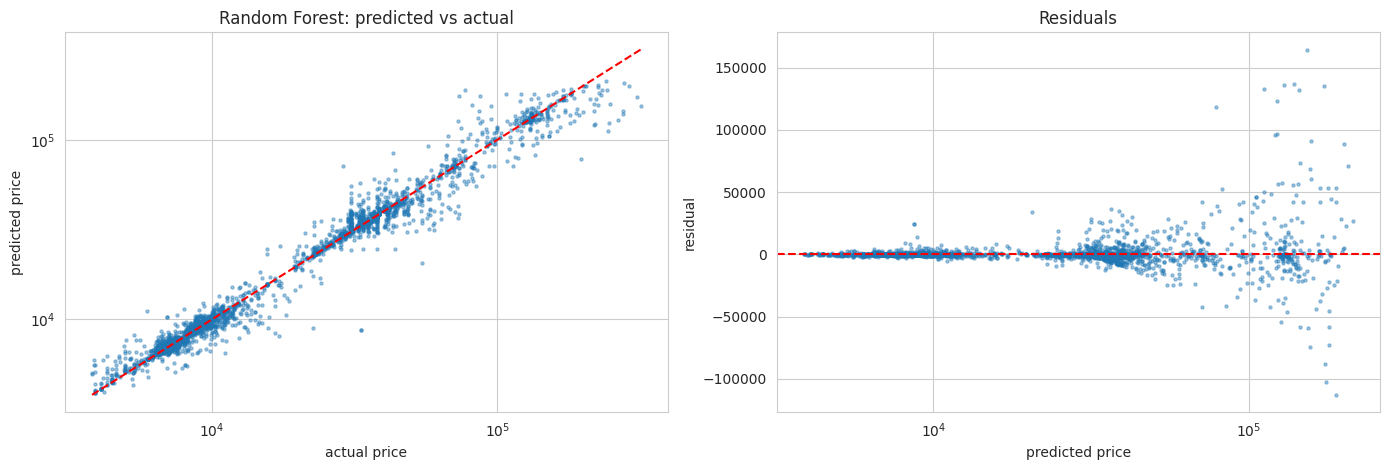

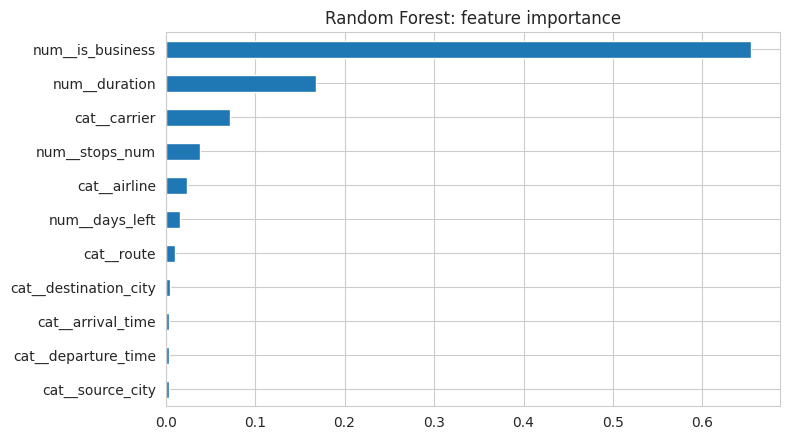

In [24]:
best_name = res.index[0]; best_pipe = RESULTS[best_name]["pipe"]
p_val = np.maximum((best_pipe.predict(X_val)), 0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(y_val, p_val, s=5, alpha=0.4); lim = [y_val.min(), y_val.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("actual price"); ax[0].set_ylabel("predicted price"); ax[0].set_title(f"{best_name}: predicted vs actual")
err = pd.DataFrame({"class": X_val["flight_class"].values, "abs_err": np.abs(y_val - p_val), "price": y_val})
print("Mean absolute error by class:\n", err.groupby("class")["abs_err"].mean().round(0))
print("(If the metric is RMSE/MAE, the Business-class errors dominate the score.)")
ax[1].scatter(p_val, y_val - p_val, s=5, alpha=0.4); ax[1].axhline(0, c="r", ls="--"); ax[1].set_xscale("log")
ax[1].set_xlabel("predicted price"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

m = unwrap(best_pipe).named_steps["model"]
if hasattr(m, "feature_importances_"):
    pd.Series(m.feature_importances_, index=unwrap(best_pipe).named_steps["prep"].get_feature_names_out()).sort_values().plot.barh(
        figsize=(8, 4.5), title=f"{best_name}: feature importance"); plt.tight_layout(); plt.show()

# **Final model**

In [25]:
import re
os.makedirs("submissions", exist_ok=True)
def make_submission(pipe, path):
    final = clone(pipe).fit(X, y)
    pred = np.maximum((final.predict(X_test)), 0)
    sub = pd.DataFrame({ID_COL: test_raw[ID_COL].values, TARGET_COL: pred})[sample_sub.columns]
    sub.to_csv(path, index=False)
    return sub

for name, r in RESULTS.items():
    f = "submissions/submission_" + re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_").lower() + ".csv"
    make_submission(r["pipe"], f); print("wrote", f)

sub = make_submission(best_pipe, "submission.csv")
assert len(sub) == len(sample_sub) and sub[ID_COL].equals(sample_sub[ID_COL])
print(f"\nBest model by validation {METRIC.upper()}: {best_name} -> submission.csv")
sub.head()

wrote submissions/submission_linear_regression.csv
wrote submissions/submission_ridge.csv


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.682e+11, tolerance: 2.387e+09
  model = cd_fast.enet_coordinate_descent(


wrote submissions/submission_lasso.csv
wrote submissions/submission_polynomial_regression.csv
wrote submissions/submission_polynomial_deg_4_ridge.csv
wrote submissions/submission_regression_tree_unpruned.csv
wrote submissions/submission_regression_tree_pre_pruned.csv
wrote submissions/submission_regression_tree_post_pruned.csv
wrote submissions/submission_random_forest.csv

Best model by validation R2: Random Forest -> submission.csv


,id,price
0,1,8483.123942
1,2,7303.706217
2,3,29348.742849
3,4,33632.865650
4,5,4409.856647


In [26]:
r2_rows = []
for name, r in RESULTS.items():
    pipe = r["pipe"]
    r2_rows.append({"model": name,
                    "train_R2": r2_score(y_tr, np.maximum(pipe.predict(X_tr), 0)),
                    "valid_R2": r2_score(y_val, np.maximum(pipe.predict(X_val), 0)),})
r2_table = pd.DataFrame(r2_rows).set_index("model").sort_values("valid_R2", ascending=False)
r2_table["gap"] = r2_table["train_R2"] - r2_table["valid_R2"]
print(r2_table.round(4))

                               train_R2  valid_R2     gap
model                                                    
Random Forest                    0.9890    0.9170  0.0720
Regression Tree (pre-pruned)     0.9522    0.9065  0.0457
Regression Tree (post-pruned)    0.9247    0.8925  0.0322
Polynomial (deg 4) + Ridge       0.9107    0.8906  0.0202
Polynomial Regression            0.9109    0.8905  0.0204
Lasso                            0.8903    0.8785  0.0118
Linear Regression                0.8903    0.8784  0.0118
Ridge                            0.8903    0.8784  0.0118
Regression Tree (unpruned)       0.9993    0.8665  0.1328
